# Model Selection & Regularization: Best Subset Selection

## Why Feature Selection?

Linear model: $$Y = \beta_0 + \beta_1 X_1 + \dots + \beta_p X_p + \epsilon$$

Fit by minimizing the residual sum of squares:
$$\hat{\beta} = \arg\min_{\beta} \sum_{i=1}^n \left(y_i - f_L(x_i)\right)^2 = \arg\min_\beta \text{RSS}$$

When $p$ is large, two problems appear:
- **Interpretability:** you can't tell which inputs actually matter.
- **Prediction accuracy:** many inputs = high flexibility = **high variance** = high test error.

**Fix: pick a subset of the most relevant inputs.**

## Three Families of Methods (roadmap for the chapter)

| Method | Idea |
|---|---|
| **Subset selection** | Search for the best subset of the original inputs |
| **Regularization** | Change the objective so some $\hat\beta_j$ shrink toward 0 |
| **Dimensionality reduction** | Build $M < p$ new "artificial" inputs from the originals |

This note covers **best subset selection** only.

## Best Subset Selection Algorithm

1. Let $\mathcal{M}_0$ be the **null model** (intercept only, no inputs).
2. For $k = 1, 2, \dots, p$:
   - Fit **all** $\binom{p}{k}$ models with exactly $k$ inputs.
   - Keep the one with the **smallest training RSS** and call it $\mathcal{M}_k$.
3. From $\mathcal{M}_0, \mathcal{M}_1, \dots, \mathcal{M}_p$, pick the single best model using **estimated test error** (e.g. K-fold cross-validation).

$$\binom{p}{k} = \frac{p!}{k!\,(p-k)!} \quad \text{(number of ways to choose } k \text{ inputs from } p\text{)}$$

### The key idea: two different criteria
- **Inside the loop (same $k$):** compare models with the same size, so **training RSS** is a fair comparison.
- **Across $k$:** training RSS **always decreases** as you add inputs, so it would always pick $\mathcal{M}_p$. You must use **test error** (CV) to choose the right flexibility.

## Computational Cost

$$\text{Total models} = \sum_{k=0}^{p}\binom{p}{k} = 2^p$$

- $p=20 \Rightarrow \approx 10^6$ models (OK)
- $p=100 \Rightarrow \approx 10^{30}$ models (impossible)

This is the main weakness. It motivates cheaper alternatives (stepwise selection, regularization).

## Formula Priority
- **Memorize:** $2^p$ total models; $\binom{p}{k}$ = number of $k$-input models.
- **Understand conceptually:** the RSS objective; why training RSS can't compare across different $k$.

## Connections
Validation set / K-fold CV (previous chapter) → used as the **final selection step** here → best subset selection → (too slow) → stepwise selection / regularization.

## Clarifications on the transcript
- "$\mathcal{M}_k$ is built from the previous model" is **misleading**: in best subset, each $k$ searches **all** $\binom{p}{k}$ subsets independently. Adding one variable to $\mathcal{M}_{k-1}$ is *forward stepwise* selection, a different (greedy) method.
- The null model is $\mathcal{M}_0$ (the transcript says "p sub 0" by mistake), and the sum $2^p$ starts at $k=0$.

## Key Takeaways
- Too many inputs gives high variance and poor interpretability, so we select features.
- Best subset: for each size $k$, keep the lowest-training-RSS model $\mathcal{M}_k$.
- Choose among $\mathcal{M}_0,\dots,\mathcal{M}_p$ with **cross-validated test error**, never training RSS.
- Training RSS always falls as $k$ grows; test error is U-shaped.
- It examines $2^p$ models, which is infeasible for large $p$.

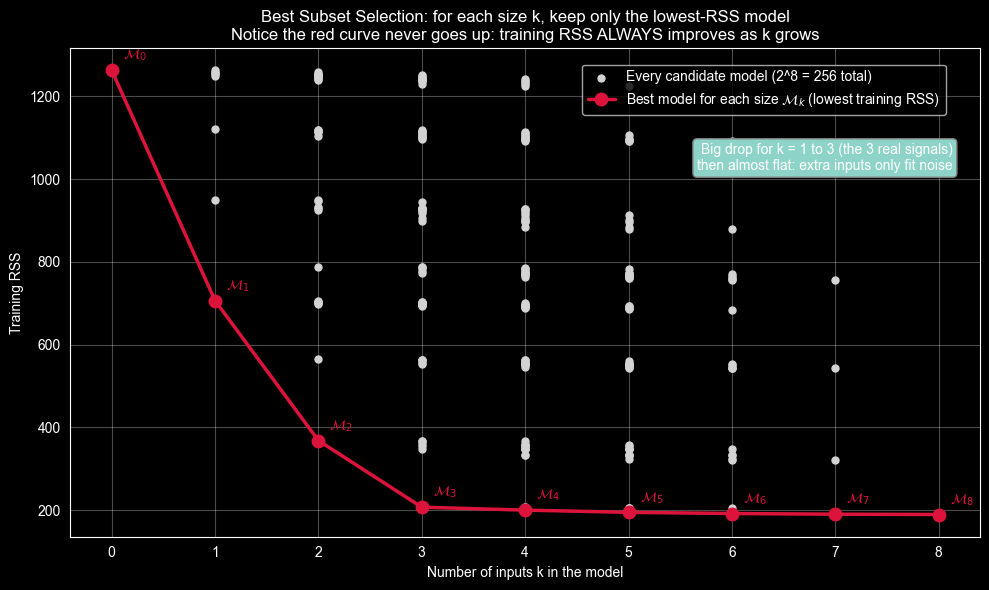

In [7]:
import numpy as np
import matplotlib.pyplot as plt
from itertools import combinations

# Simulate data: only the first 3 of 8 inputs truly matter
rng = np.random.default_rng(0)
n, p = 100, 8
X = rng.normal(size=(n, p))
beta_true = np.array([3, 2, 1.5, 0, 0, 0, 0, 0])
y = 1 + X @ beta_true + rng.normal(scale=2, size=n)

def rss(cols):
    """Fit OLS on the chosen columns (plus intercept) and return the training RSS."""
    A = np.column_stack([np.ones(n)] + [X[:, j] for j in cols])
    b, *_ = np.linalg.lstsq(A, y, rcond=None)
    r = y - A @ b
    return r @ r

all_k, all_rss = [], []
best = {}  # best[k] = (smallest RSS, columns used)
for k in range(0, p + 1):
    for cols in combinations(range(p), k):   # ALL p-choose-k models
        v = rss(cols)
        all_k.append(k); all_rss.append(v)
        if k not in best or v < best[k][0]:
            best[k] = (v, cols)

ks = sorted(best)
best_rss = [best[k][0] for k in ks]

fig, ax = plt.subplots(figsize=(10, 6))
ax.scatter(all_k, all_rss, color="lightgray", s=25, label="Every candidate model (2^8 = 256 total)")
ax.plot(ks, best_rss, "o-", color="crimson", lw=2.5, ms=9, label=r"Best model for each size $\mathcal{M}_k$ (lowest training RSS)")
for k in ks:
    ax.annotate(rf"$\mathcal{{M}}_{k}$", (k, best[k][0]), textcoords="offset points", xytext=(8, 8), color="crimson")
ax.set_xlabel("Number of inputs k in the model")
ax.set_ylabel("Training RSS")
ax.set_title("Best Subset Selection: for each size k, keep only the lowest-RSS model\n"
             "Notice the red curve never goes up: training RSS ALWAYS improves as k grows", fontsize=12)
ax.text(0.97, 0.75, "Big drop for k = 1 to 3 (the 3 real signals)\nthen almost flat: extra inputs only fit noise",
        transform=ax.transAxes, ha="right", fontsize=10,
        bbox=dict(boxstyle="round", ec="gray"))
ax.legend(loc="upper right", bbox_to_anchor=(0.97, 0.98))
ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

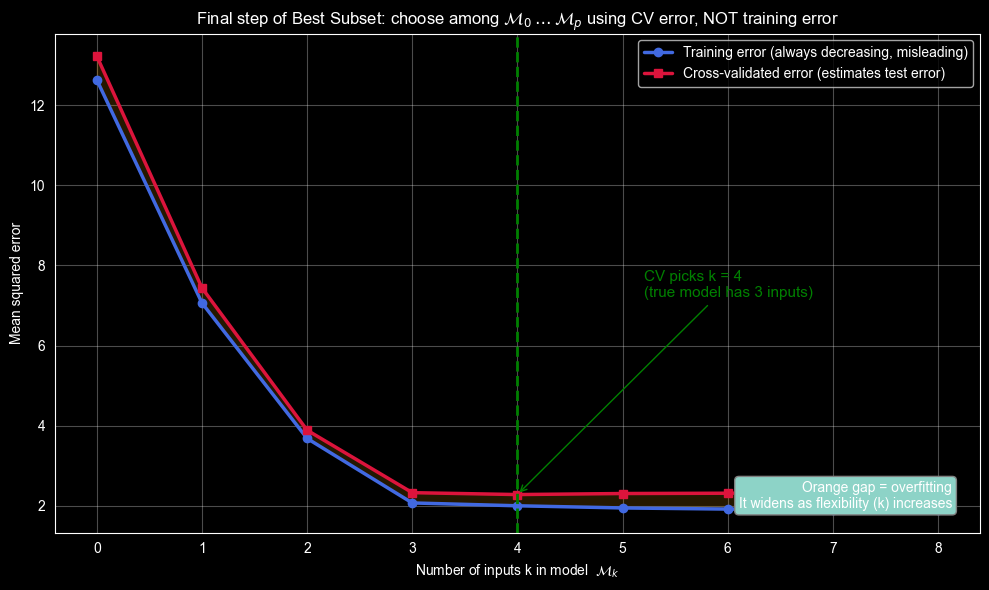

In [8]:
import numpy as np
import matplotlib.pyplot as plt
from itertools import combinations
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import cross_val_score, KFold

# Same simulated data as before (only first 3 inputs matter)
rng = np.random.default_rng(0)
n, p = 100, 8
X = rng.normal(size=(n, p))
beta_true = np.array([3, 2, 1.5, 0, 0, 0, 0, 0])
y = 1 + X @ beta_true + rng.normal(scale=2, size=n)

def train_mse(cols):
    """Training MSE of an OLS model using only `cols` as inputs."""
    if len(cols) == 0:
        return np.mean((y - y.mean()) ** 2)
    model = LinearRegression().fit(X[:, cols], y)
    return np.mean((y - model.predict(X[:, cols])) ** 2)

def cv_mse(cols, folds=5):
    """5-fold cross-validated MSE of an OLS model using only `cols`."""
    if len(cols) == 0:
        # Null model: predict the training-fold mean
        errs = []
        for tr, te in KFold(folds, shuffle=True, random_state=1).split(X):
            errs.append(np.mean((y[te] - y[tr].mean()) ** 2))
        return np.mean(errs)
    scores = cross_val_score(LinearRegression(), X[:, list(cols)], y,
                             cv=KFold(folds, shuffle=True, random_state=1),
                             scoring="neg_mean_squared_error")
    return -scores.mean()

# Step 2 of the algorithm: best model M_k for each k (by training error)
M = {}
for k in range(0, p + 1):
    M[k] = min(combinations(range(p), k), key=lambda c: train_mse(list(c)))

# Step 3: estimate test error of each M_k with CV
ks = list(range(0, p + 1))
train_err = [train_mse(list(M[k])) for k in ks]
cv_err = [cv_mse(list(M[k])) for k in ks]
k_star = ks[int(np.argmin(cv_err))]

fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(ks, train_err, "o-", color="royalblue", lw=2.5, label="Training error (always decreasing, misleading)")
ax.plot(ks, cv_err, "s-", color="crimson", lw=2.5, label="Cross-validated error (estimates test error)")
ax.axvline(k_star, color="green", ls="--", lw=2)
ax.annotate(f"CV picks k = {k_star}\n(true model has 3 inputs)",
            xy=(k_star, min(cv_err)), xytext=(k_star + 1.2, min(cv_err) + (max(cv_err) - min(cv_err)) * 0.45),
            arrowprops=dict(arrowstyle="->", color="green"), color="green", fontsize=11)
ax.fill_between(ks, train_err, cv_err, color="orange", alpha=0.15)
ax.text(0.97, 0.05, "Orange gap = overfitting\nIt widens as flexibility (k) increases",
        transform=ax.transAxes, ha="right", fontsize=10,
        bbox=dict(boxstyle="round", ec="gray"))
ax.set_xlabel("Number of inputs k in model  $\\mathcal{M}_k$")
ax.set_ylabel("Mean squared error")
ax.set_title("Final step of Best Subset: choose among $\\mathcal{M}_0 \\dots \\mathcal{M}_p$ using CV error, NOT training error",
             fontsize=12)
ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

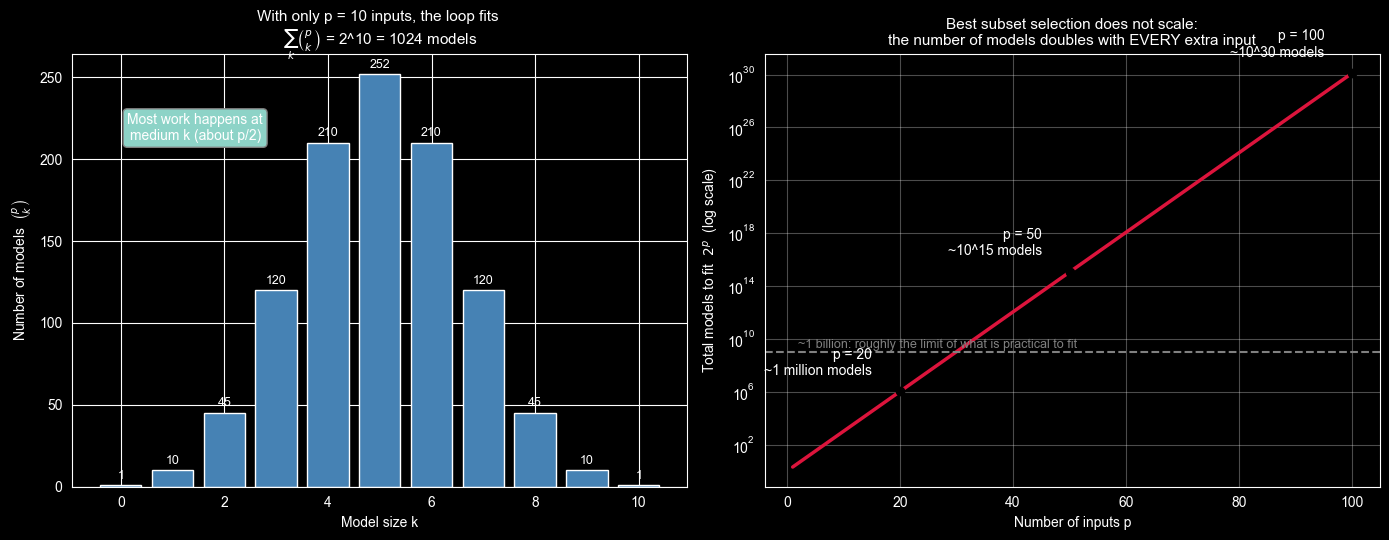

In [6]:
import numpy as np
import matplotlib.pyplot as plt
from math import comb

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.5))

# Left: how many models must be fit at each size k, for p = 10
p = 10
ks = np.arange(0, p + 1)
counts = [comb(p, k) for k in ks]
bars = ax1.bar(ks, counts, color="steelblue")
for k, c in zip(ks, counts):
    ax1.text(k, c + 4, str(c), ha="center", fontsize=9)
ax1.set_xlabel("Model size k")
ax1.set_ylabel(r"Number of models  $\binom{p}{k}$")
ax1.set_title(f"With only p = {p} inputs, the loop fits \n" + r"$\sum_k \binom{p}{k}$" + f" = 2^{p} = {2**p} models", fontsize=11)
ax1.text(0.2, 0.8, "Most work happens at\nmedium k (about p/2)", transform=ax1.transAxes,
         ha="center", bbox=dict(boxstyle="round", ec="gray"))

# Right: total models 2^p as p grows (log scale)
ps = np.arange(1, 101)
ax2.plot(ps, [2.0 ** x for x in ps], color="crimson", lw=2.5)
ax2.set_yscale("log")
for pv, label in [(20, "p = 20\n~1 million models"), (50, "p = 50\n~10^15 models"), (100, "p = 100\n~10^30 models")]:
    ax2.scatter(pv, 2.0 ** pv, color="black", zorder=5)
    ax2.annotate(label, (pv, 2.0 ** pv), textcoords="offset points", xytext=(-20, 12),
                 ha="right", fontsize=10)
ax2.axhline(1e9, color="gray", ls="--")
ax2.text(2, 2e9, "~1 billion: roughly the limit of what is practical to fit", fontsize=9, color="gray")
ax2.set_xlabel("Number of inputs p")
ax2.set_ylabel("Total models to fit  $2^p$  (log scale)")
ax2.set_title("Best subset selection does not scale:\nthe number of models doubles with EVERY extra input", fontsize=11)
ax2.grid(alpha=0.3, which="both")

plt.tight_layout(); plt.show()

# Stepwise Selection: Cheaper Alternatives to Best Subset

## Why Stepwise?
Best subset must fit $2^p$ models. Stepwise methods search a **path** of models instead of all subsets, trading a little model quality for a huge computational saving.

## Forward Stepwise Selection
1. Start with the null model $\mathcal{M}_0$ (intercept only).
2. For $k = 0, 1, \dots, p-1$:
   - Fit the $p-k$ models that **add one new input** to $\mathcal{M}_k$.
   - Keep the one with the **smallest training RSS** as $\mathcal{M}_{k+1}$.
3. Pick the best of $\mathcal{M}_0, \dots, \mathcal{M}_p$ using **cross-validated test error**.

**Key property:** once a variable enters, it **stays in** (greedy, no going back).

## Backward Stepwise Selection
1. Start with the **full model** $\mathcal{M}_p$ (all inputs).
2. For $k = p, p-1, \dots, 1$:
   - Fit the $k$ models that **remove one input** from $\mathcal{M}_k$.
   - Keep the one with the **smallest training RSS** as $\mathcal{M}_{k-1}$.
3. Pick the best of $\mathcal{M}_p, \dots, \mathcal{M}_0$ using **cross-validated test error**.

**Key property:** once a variable is removed, it **stays out**.

## Computational Cost
Both methods fit

$$1 + \sum_{k=0}^{p-1}(p-k) = 1 + \frac{p(p+1)}{2} \text{ models}$$

| Method | Models fit | Finds the best model of each size? |
|---|---|---|
| Best subset | $2^p$ | **Yes, guaranteed** |
| Forward stepwise | $1 + p(p+1)/2$ | No (greedy) |
| Backward stepwise | $1 + p(p+1)/2$ | No (greedy) |

For $p = 20$: best subset fits about 1,000,000 models, stepwise fits 211.

## Why Stepwise Can Miss the Best Model
A variable that looks bad alone can be very useful **in combination** with another. Greedy methods can't see that, because they commit to each choice. Best subset checks every combination, so it can.

## Credit Dataset Example (best subset, $p = 11$)
- **Left plot:** gray dots = training RSS of all $2^{11}$ models; red dots = lowest RSS for each size $k$ (these are $\mathcal{M}_1,\dots,\mathcal{M}_{11}$). E.g. the red dot at $k=6$ is the best of $\binom{11}{6}$ models.
- **Right plot:** 10-fold CV test MSE of each $\mathcal{M}_k$. The minimum is at $\mathcal{M}_6$.
- **Practical tip:** $\mathcal{M}_4$ has a **comparable CV MSE** and is simpler, so it's often the better choice (simpler = more interpretable, less variance).

## Formula Priority
- **Memorize:** cost comparison, $2^p$ vs $1 + p(p+1)/2$.
- **Understand conceptually:** greedy vs exhaustive search; training RSS within a given $k$, CV error across $k$.

## Connections
Best subset (exhaustive, $2^p$) → too expensive → forward / backward stepwise (greedy, about $p^2/2$) → all methods finish with the **same CV step** to choose $k$.

## Clarifications on the transcript
- The transcript says "we are guaranteed to find the best possible model in the forward stepwise selection." This is garbled. The correct statement: **best subset** is guaranteed to find the best model of each size; **forward stepwise is not**, but it is much cheaper.
- "We'll have $p-1$ models from $\mathcal{M}_p$ up to $\mathcal{M}_1$ and finally $\mathcal{M}_0$" is a slip. Backward selection produces $p+1$ models in total: $\mathcal{M}_p,\dots,\mathcal{M}_0$.
- Extra (not in the lecture): backward selection needs $n > p$ so the full model can be fit; forward selection still works when $p > n$.

## Key Takeaways
- Forward = start empty, **add** the best variable each step. Backward = start full, **remove** the least useful each step.
- Both fit about $p^2/2$ models instead of $2^p$.
- Both are **greedy**, so they are not guaranteed to match best subset's models.
- Use training RSS to compare models of the **same size**, and CV error to choose the **size**.
- Prefer a simpler model whose CV error is comparable to the minimum (e.g. $\mathcal{M}_4$ vs $\mathcal{M}_6$).

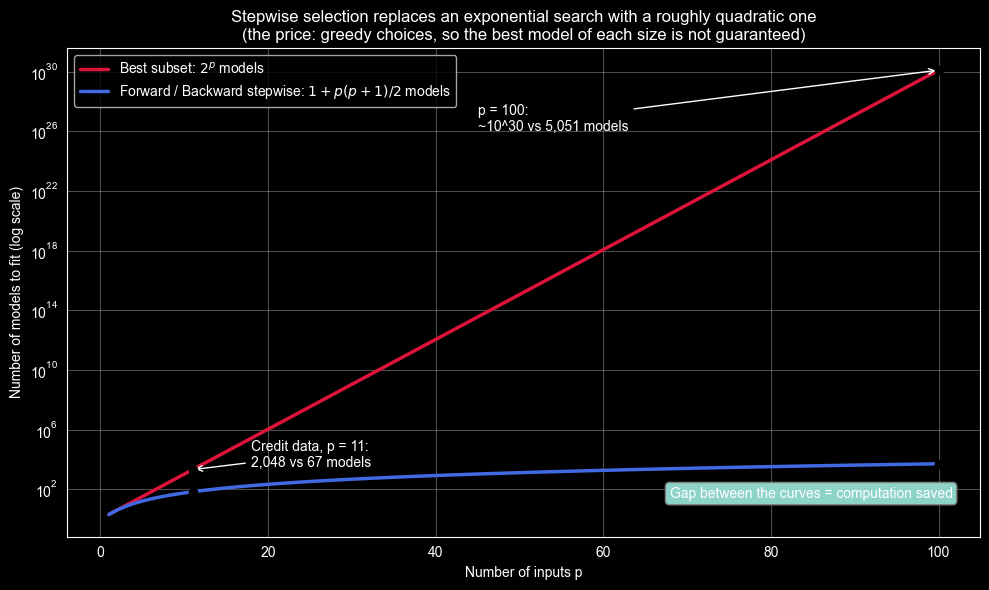

In [14]:
import numpy as np
import matplotlib.pyplot as plt

p = np.arange(1, 101)
best_subset = 2.0 ** p                 # exhaustive search: 2^p models
stepwise = 1 + p * (p + 1) / 2         # forward or backward: 1 + p(p+1)/2 models

fig, ax = plt.subplots(figsize=(10, 6))
ax.semilogy(p, best_subset, color="crimson", lw=2.5, label=r"Best subset: $2^p$ models")
ax.semilogy(p, stepwise, color="royalblue", lw=2.5, label=r"Forward / Backward stepwise: $1 + p(p+1)/2$ models")

# Highlight the Credit dataset (p = 11) and a large p = 100 case
for pv, dy in [(11, 0), (100, 0)]:
    ax.scatter([pv, pv], [2.0 ** pv, 1 + pv * (pv + 1) / 2], color="black", zorder=5)
ax.annotate("Credit data, p = 11:\n2,048 vs 67 models", (11, 2.0 ** 11), xytext=(18, 3e3),
            arrowprops=dict(arrowstyle="->"), fontsize=10)
ax.annotate("p = 100:\n~10^30 vs 5,051 models", (100, 2.0 ** 100), xytext=(45, 1e26),
            arrowprops=dict(arrowstyle="->"), fontsize=10)

ax.set_xlabel("Number of inputs p")
ax.set_ylabel("Number of models to fit (log scale)")
ax.set_title("Stepwise selection replaces an exponential search with a roughly quadratic one\n"
             "(the price: greedy choices, so the best model of each size is not guaranteed)", fontsize=12)
ax.text(0.97, 0.08, "Gap between the curves = computation saved",
        transform=ax.transAxes, ha="right", fontsize=10,
        bbox=dict(boxstyle="round",  ec="gray"))
ax.legend(loc="upper left"); ax.grid(alpha=0.3, which="both")
plt.tight_layout(); plt.show()

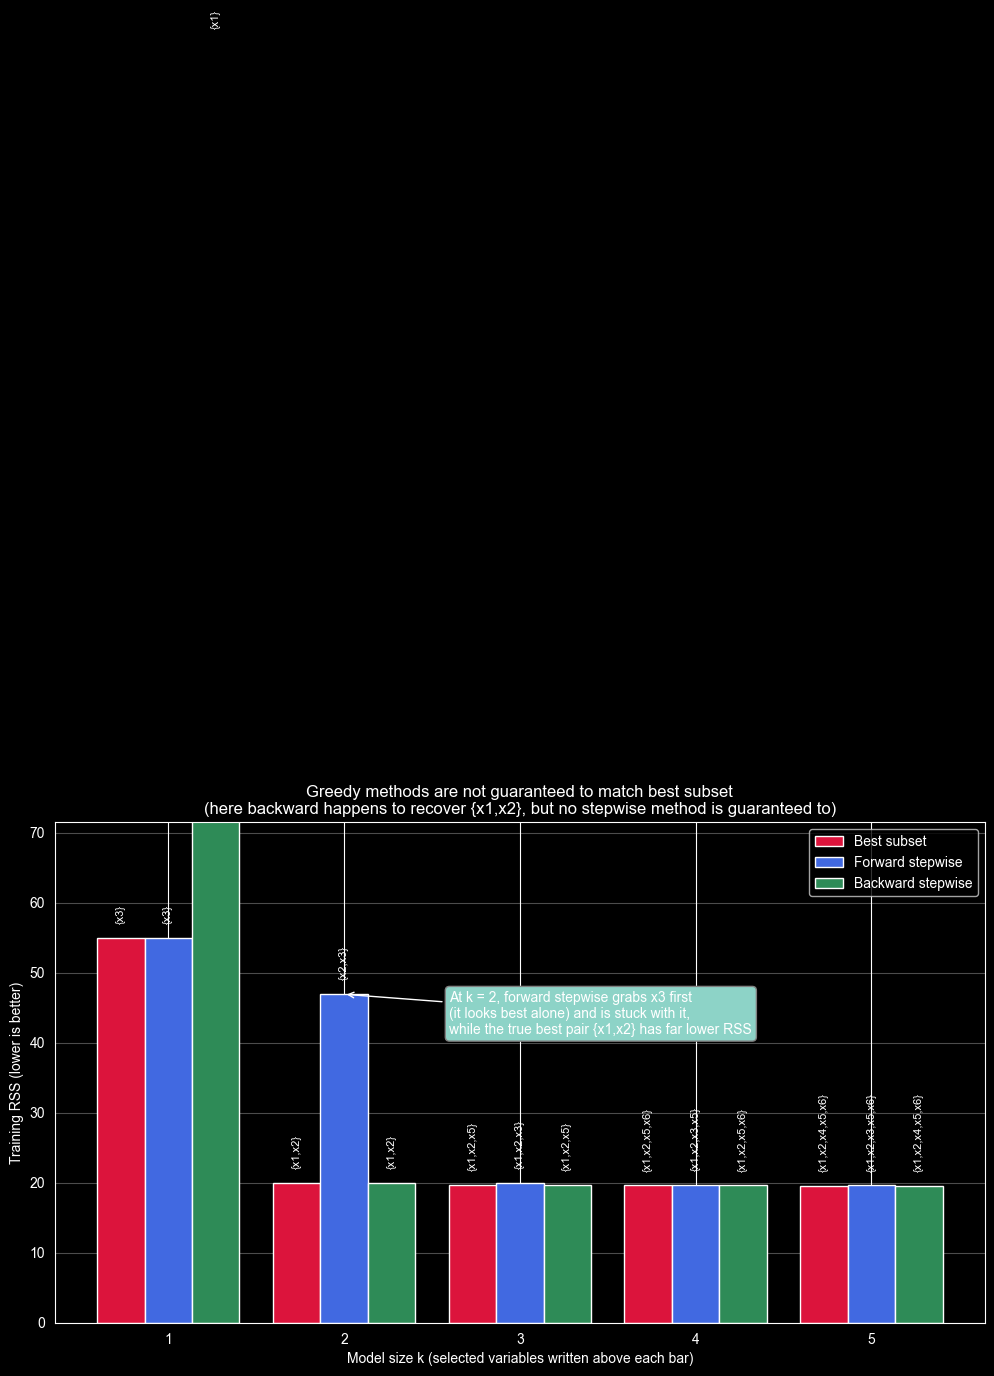

In [15]:
import numpy as np
import matplotlib.pyplot as plt
from itertools import combinations
import warnings
warnings.filterwarnings("ignore")

# Constructed data: y = x1 + x2, but x3 is a noisy copy of (x1 + x2),
# so x3 LOOKS best alone while the truly best pair is {x1, x2}
rng = np.random.default_rng(1)
n = 200
x1, x2 = rng.normal(size=n), rng.normal(size=n)
x3 = (x1 + x2) / np.sqrt(2) + 0.3 * rng.normal(size=n)
noise = rng.normal(size=(n, 3))                      # x4, x5, x6 are pure noise
X = np.column_stack([x1, x2, x3, noise])
names = ["x1", "x2", "x3", "x4", "x5", "x6"]
y = x1 + x2 + 0.3 * rng.normal(size=n)
p = X.shape[1]

def rss(cols):
    """Training RSS of an OLS fit using the given columns (plus intercept)."""
    A = np.column_stack([np.ones(n)] + [X[:, j] for j in cols])
    b, *_ = np.linalg.lstsq(A, y, rcond=None)
    r = y - A @ b
    return r @ r

# Best subset: try every combination of size k
best = {k: min(combinations(range(p), k), key=rss) for k in range(1, p + 1)}

# Forward stepwise: greedily ADD the variable that lowers RSS most; never remove
fwd, cur = {}, []
for k in range(1, p + 1):
    j = min([c for c in range(p) if c not in cur], key=lambda c: rss(cur + [c]))
    cur = cur + [j]
    fwd[k] = tuple(sorted(cur))

# Backward stepwise: start full, greedily REMOVE the variable that hurts RSS least
bwd, cur = {p: tuple(range(p))}, list(range(p))
for k in range(p, 1, -1):
    j = min(cur, key=lambda c: rss([v for v in cur if v != c]))
    cur = [v for v in cur if v != j]
    bwd[k - 1] = tuple(cur)

label = lambda cols: "{" + ",".join(names[j] for j in cols) + "}"
ks = np.arange(1, 6)
w = 0.27
fig, ax = plt.subplots(figsize=(12, 6.5))
for off, d, color, nm in [(-w, best, "crimson", "Best subset"),
                          (0, fwd, "royalblue", "Forward stepwise"),
                          (w, bwd, "seagreen", "Backward stepwise")]:
    vals = [rss(d[k]) for k in ks]
    ax.bar(ks + off, vals, width=w, color=color, label=nm)
    for k, v in zip(ks, vals):
        ax.text(k + off, v + 2, label(d[k]), rotation=90, ha="center", va="bottom", fontsize=8)

ax.annotate("At k = 2, forward stepwise grabs x3 first\n(it looks best alone) and is stuck with it,\n"
            "while the true best pair {x1,x2} has far lower RSS",
            xy=(2, rss(fwd[2])), xytext=(2.6, rss(fwd[1]) * 0.75),
            arrowprops=dict(arrowstyle="->"), fontsize=10,
            bbox=dict(boxstyle="round",  ec="gray"))
ax.set_xticks(ks)
ax.set_ylim(0, rss(fwd[1]) * 1.3)
ax.set_xlabel("Model size k (selected variables written above each bar)")
ax.set_ylabel("Training RSS (lower is better)")
ax.set_title("Greedy methods are not guaranteed to match best subset\n"
             "(here backward happens to recover {x1,x2}, but no stepwise method is guaranteed to)", fontsize=12)
ax.legend(); ax.grid(alpha=0.3, axis="y")
plt.tight_layout(); plt.show()

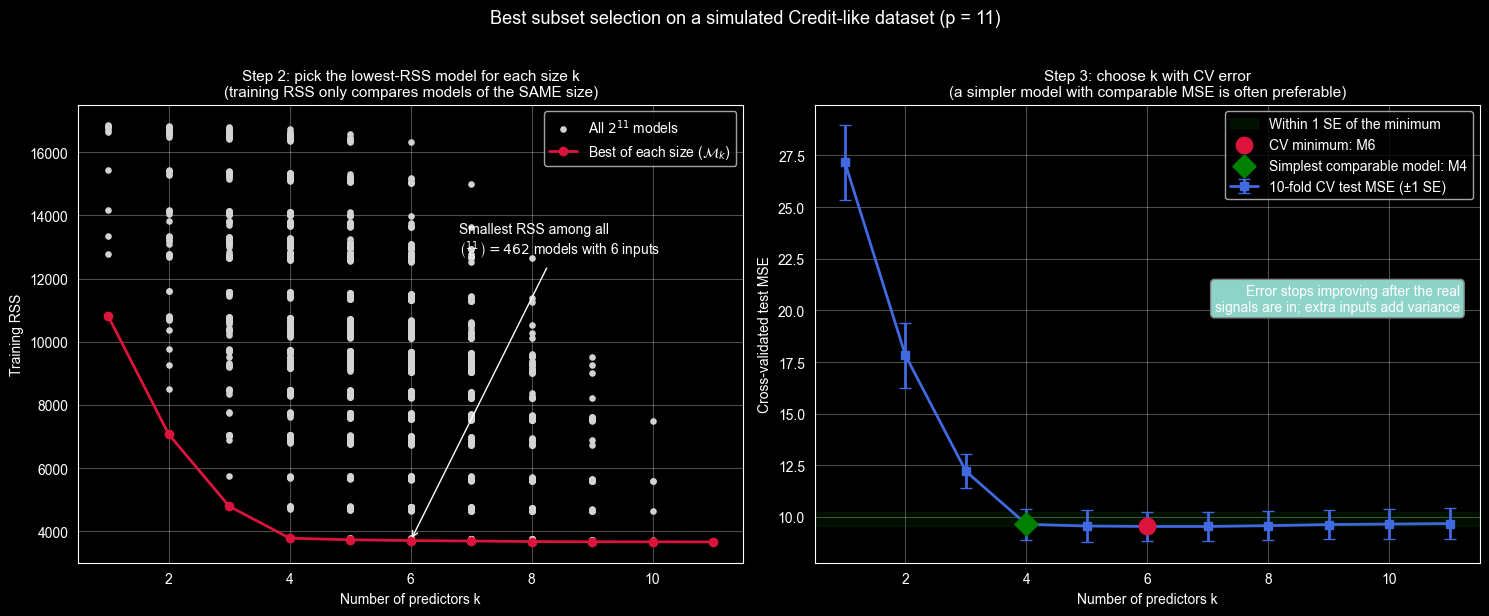

In [16]:
import numpy as np
import matplotlib.pyplot as plt
from itertools import combinations
from sklearn.model_selection import KFold

# Simulated stand-in for the Credit data: 11 predictors, only a few really matter
rng = np.random.default_rng(3)
n, p = 400, 11
Z = rng.normal(size=(n, p))
X = Z.copy()
X[:, 1] = 0.8 * Z[:, 0] + 0.6 * Z[:, 1]               # correlated predictors (like limit/rating)
beta = np.array([4, 0, 3, 2, 1.5, 0.4, 0, 0, 0.3, 0, 0])
y = X @ beta + rng.normal(scale=3, size=n)

def fit_rss(cols, Xa, ya):
    """OLS fit on (Xa, ya); return coefficients and RSS."""
    A = np.column_stack([np.ones(len(ya))] + [Xa[:, j] for j in cols])
    b, *_ = np.linalg.lstsq(A, ya, rcond=None)
    r = ya - A @ b
    return b, r @ r

# Left plot data: RSS of ALL 2^11 - 1 models, and the best (red) for each size k
all_k, all_rss, best = [], [], {}
for k in range(1, p + 1):
    for cols in combinations(range(p), k):
        v = fit_rss(cols, X, y)[1]
        all_k.append(k); all_rss.append(v)
        if k not in best or v < best[k][0]:
            best[k] = (v, cols)
ks = np.arange(1, p + 1)

# Right plot data: 10-fold CV test MSE of each M_k
fold_mse = np.zeros((10, p))
for f, (tr, te) in enumerate(KFold(10, shuffle=True, random_state=0).split(X)):
    for k in ks:
        cols = best[k][1]
        b, _ = fit_rss(cols, X[tr], y[tr])
        A_te = np.column_stack([np.ones(len(te))] + [X[te][:, j] for j in cols])
        fold_mse[f, k - 1] = np.mean((y[te] - A_te @ b) ** 2)
cv_mean = fold_mse.mean(axis=0)
cv_se = fold_mse.std(axis=0, ddof=1) / np.sqrt(10)
k_min = ks[np.argmin(cv_mean)]
threshold = cv_mean.min() + cv_se[np.argmin(cv_mean)]
k_simple = ks[np.where(cv_mean <= threshold)[0][0]]     # smallest k with comparable CV error

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

# Left: training RSS of all models
ax1.scatter(all_k, all_rss, color="lightgray", s=14, label=r"All $2^{11}$ models")
ax1.plot(ks, [best[k][0] for k in ks], "o-", color="crimson", lw=2, label=r"Best of each size ($\mathcal{M}_k$)")
ax1.annotate(r"Smallest RSS among all" "\n" r"$\binom{11}{6} = 462$ models with 6 inputs",
             xy=(6, best[6][0]), xytext=(6.8, np.percentile(all_rss, 85)),
             arrowprops=dict(arrowstyle="->"), fontsize=10)
ax1.set_xlabel("Number of predictors k"); ax1.set_ylabel("Training RSS")
ax1.set_title("Step 2: pick the lowest-RSS model for each size k\n(training RSS only compares models of the SAME size)", fontsize=11)
ax1.legend(); ax1.grid(alpha=0.3)

# Right: CV error
ax2.errorbar(ks, cv_mean, yerr=cv_se, fmt="s-", color="royalblue", lw=2, capsize=4,
             label="10-fold CV test MSE (±1 SE)")
ax2.axhspan(cv_mean.min(), threshold, color="green", alpha=0.12, label="Within 1 SE of the minimum")
ax2.scatter([k_min], [cv_mean[k_min - 1]], color="crimson", s=140, zorder=5, label=f"CV minimum: M{k_min}")
ax2.scatter([k_simple], [cv_mean[k_simple - 1]], color="green", s=140, marker="D", zorder=5,
            label=f"Simplest comparable model: M{k_simple}")
ax2.set_xlabel("Number of predictors k"); ax2.set_ylabel("Cross-validated test MSE")
ax2.set_title("Step 3: choose k with CV error\n(a simpler model with comparable MSE is often preferable)", fontsize=11)
ax2.text(0.97, 0.55, "Error stops improving after the real\nsignals are in; extra inputs add variance",
         transform=ax2.transAxes, ha="right", fontsize=10,
         bbox=dict(boxstyle="round",  ec="gray"))
ax2.legend(loc="upper right"); ax2.grid(alpha=0.3)

plt.suptitle("Best subset selection on a simulated Credit-like dataset (p = 11)", fontsize=13, y=1.02)
plt.tight_layout(); plt.show()